# Drug-regulon network: staggered fans and single shared TF nodes

This notebook draws completed association results locally. It does not rerun
SCENIC, require Apptainer, or modify your source CSV files.

Inspired by your **Olig2 GRN downstream with lineage specificity visualization**
notebook (polar fan positions and curved connections), and the visual structure
of [Figure 2e](https://www.nature.com/articles/s41592-025-02927-5/figures/2).
This is a custom layout, not the paper's original layout algorithm.

**What is fixed:**
- At most 20 highest-importance associations per drug, after the weight filter.
- Every regulon appears exactly once, including shared regulons.
- Drugs are spread horizontally in staggered rows. Similar displayed TF sets
  are placed nearby using Jaccard distance and optimal hierarchical ordering.
- Each TF has a *layout host*, chosen from its connected drugs. Shared TFs
  prefer the host's fan boundaries facing other connected drugs.
- TFs are split above/below their host with a reproducible random seed.
- Other connected drugs link to the same TF node. There are no invented
  drug-drug, TF-TF, or cell-type edges.

**Interpretation:** black boxes are drugs; colored nodes are regulons. Color
indicates the highest-mean-AUC cell type in `regulon_nodes.csv`, not an inferred
cell-type-specific drug effect. Node area represents target-gene count.
Line width and darkness represent unsigned GRNBoost2 importance, not direction,
effect size or significance. The above/below split has no biological meaning.

A layout host is only a drawing anchor, NOT an exclusive biological assignment.
If most TFs are shared, it is impossible to put a separate full circle of TFs
around every drug while also showing each TF only once. The top-20 cap counts
incident drug-TF edges, not the number of TF nodes physically near a drug.

## Install once in the notebook's Python environment

```bash
conda install -c conda-forge numpy pandas scipy matplotlib adjusttext ipykernel
```

Run cells from top to bottom. Change `DATA_DIR` and the parameters below.

In [1]:
import hashlib
import json
import math
import warnings
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MplPath
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist, squareform
from adjustText import adjust_text
from IPython.display import display

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})

## 1. Parameters

Defaults follow your latest local R setup: `with_DMSO`, **importance > 50**,
but the cap is now **20**. Set `min_importance=200` to use the earlier strict
>200 cutoff. No importance-share threshold is applied.

DMSO is treated like every other condition. It needs real association rows;
this notebook never creates a DMSO edge or an edge below the weight threshold.
Drugs without passing edges are omitted by default and reported in the audit.

To make a smaller panel, set `drugs_to_plot` to a list, for example
`["dmso", "m114", "m118", "m124", "m131", "m135"]`.
Increase `drug_columns` for a wider panel, or set it to the number of drugs
to place them all in one staggered horizontal strip. More drugs require a
larger canvas; PDF and SVG remain zoomable vector graphics.

In [2]:
DATA_DIR = Path("/home/jiafzhou/GRN_org/analysis/drug_regulon_network_with_dmso")
CFG = {
    "association_file": str(DATA_DIR / "drug_regulon_associations.csv"),
    "node_file": str(DATA_DIR / "regulon_nodes.csv"),
    "target_counts_file": str(DATA_DIR / "regulon_target_counts.csv"),
    "output_dir": str(DATA_DIR / "figures_drug_select"),
    "min_importance": 50.0,  # Strict >; change to 200.0 if desired.
    "top_n": 20,             # Hard maximum of 20; can be reduced.
    "drugs_to_plot": ["dmso", "m114", "m124", "m135", "m118", "m131"],   # None = all conditions in the association CSV.
    "keep_empty_drugs": False,
    "drug_order": None,      # Optional complete order of the displayed drugs.
    "drug_columns": 7,
    "seed": 42,
    "drug_spacing_x": 6.8,
    "drug_spacing_y": 5.8,
    "stagger_y": 0.65,
    "fan_radius_x": 2.0,
    "fan_base_y": 0.9,
    "fan_height_y": 0.95,
    "host_balance_penalty": 0.075,
    "edge_width_range": [0.25, 2.0],
    "local_edge_alpha": 0.72,
    "shared_edge_alpha": 0.38,
    "max_node_area": 300.0,  # Points squared; area proportional to target count.
    "label_fontsize": 9.5,
    "drug_fontsize": 10.5,
    "adjust_labels": True,
    "celltype_colors": {},  # Optional {"RG": "#59A14F", ...}.
    "drug_positions": {},   # Optional {"dmso": [x, y], ...}; display override.
    "regulon_positions": {},# Optional {"SOX2(+)": [x, y], ...}; one node per name.
    "figsize": None,        # None = adaptive; or [width_inches, height_inches].
    "png_dpi": 200,
    "output_stem": "drug_regulon_fan_panel",
}

## 2. Load, validate and select edges

Required files: `drug_regulon_associations.csv` (drug, regulon, importance),
`regulon_nodes.csv` (regulon, max_activity_celltype), and
`regulon_target_counts.csv` (regulon, target_count). Use matching exports from
the same fitted model and pooled regulon reference.

Duplicate drug-regulon pairs retain their largest weight. The cutoff is
applied BEFORE top-20 selection. Missing annotations or target counts are
errors rather than silently dropped TFs.

In [3]:
def read_csv_checked(path, required):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}")
    frame = pd.read_csv(path, keep_default_na=False)
    missing = set(required) - set(frame.columns)
    if missing or frame.empty:
        raise ValueError(f"{path}: empty table or missing columns {sorted(missing)}")
    return frame


def load_and_select(cfg):
    if isinstance(cfg["top_n"], bool) or not 1 <= cfg["top_n"] <= 20 or int(cfg["top_n"]) != cfg["top_n"]:
        raise ValueError("top_n must be an integer between 1 and 20")
    if not np.isfinite(cfg["min_importance"]) or cfg["min_importance"] < 0:
        raise ValueError("min_importance must be finite and nonnegative")
    edges = read_csv_checked(cfg["association_file"], ["drug", "regulon", "importance"])
    annotations = read_csv_checked(cfg["node_file"], ["regulon", "max_activity_celltype"])
    counts = read_csv_checked(cfg["target_counts_file"], ["regulon", "target_count"])
    for frame, columns in [(edges, ["drug", "regulon"]), (annotations, ["regulon"]), (counts, ["regulon"])]:
        for column in columns:
            frame[column] = frame[column].astype(str).str.strip()
            if frame[column].eq("").any():
                raise ValueError(f"Blank {column} value")
    if annotations.regulon.duplicated().any() or counts.regulon.duplicated().any():
        raise ValueError("Regulon annotation/count rows must be unique")
    edges["importance"] = pd.to_numeric(edges["importance"], errors="raise")
    counts["target_count"] = pd.to_numeric(counts["target_count"], errors="raise")
    if not np.isfinite(edges.importance).all() or edges.importance.lt(0).any():
        raise ValueError("Importance must be finite and nonnegative")
    if not np.isfinite(counts.target_count).all() or counts.target_count.le(0).any() or (counts.target_count % 1 != 0).any():
        raise ValueError("Target counts must be positive integers")
    annotations["celltype"] = annotations["max_activity_celltype"].astype(str).str.strip()
    blank = annotations.celltype.str.lower().isin(["", "nan", "none", "<na>"])
    annotations.loc[blank, "celltype"] = "Unassigned"
    if edges.duplicated(["drug", "regulon"]).any():
        warnings.warn("Duplicate drug-regulon associations: retaining the largest importance")
    edges = edges.sort_values(["importance", "drug", "regulon"], ascending=[False, True, True])
    edges = edges.drop_duplicates(["drug", "regulon"], keep="first")
    requested = sorted(edges.drug.unique()) if cfg["drugs_to_plot"] is None else list(dict.fromkeys(cfg["drugs_to_plot"]))
    missing = set(requested) - set(edges.drug)
    if missing:
        raise ValueError(f"Requested drugs missing from the association CSV: {sorted(missing)}")
    edges = edges[edges.drug.isin(requested)].copy()
    above = edges[edges.importance > cfg["min_importance"]].copy()
    selected = above.sort_values(["drug", "importance", "regulon"], ascending=[True, False, True])
    selected = selected.groupby("drug", sort=False).head(int(cfg["top_n"])).copy()
    if selected.empty:
        raise ValueError("No associations pass the weight filter. Check min_importance.")
    selected["rank_within_drug"] = selected.groupby("drug").cumcount() + 1
    for source, label in [(annotations, "cell-type annotations"), (counts, "target counts")]:
        absent = set(selected.regulon) - set(source.regulon)
        if absent:
            raise ValueError(f"Missing {label}: {sorted(absent)}")
    nodes = annotations[["regulon", "celltype"]].merge(counts[["regulon", "target_count"]],
                                                       on="regulon", validate="one_to_one")
    nodes = nodes[nodes.regulon.isin(selected.regulon)].sort_values("regulon").reset_index(drop=True)
    nodes["drug_degree"] = nodes.regulon.map(selected.groupby("regulon").drug.nunique())
    nodes["shared"] = nodes.drug_degree.gt(1)
    selected = selected.merge(nodes[["regulon", "celltype", "shared"]], on="regulon", validate="many_to_one")
    audit = pd.DataFrame(index=pd.Index(requested, name="drug"))
    audit["input_edges"] = edges.groupby("drug").size().reindex(requested, fill_value=0)
    audit["maximum_importance"] = edges.groupby("drug").importance.max().reindex(requested)
    audit["edges_above_threshold"] = above.groupby("drug").size().reindex(requested, fill_value=0)
    audit["displayed_edges"] = selected.groupby("drug").size().reindex(requested, fill_value=0)
    audit["shown_as_node"] = audit.displayed_edges.gt(0) | cfg["keep_empty_drugs"]
    drugs = audit.index[audit.shown_as_node].tolist()
    all_types = sorted(annotations.celltype.unique())
    palette = plt.get_cmap("tab20")
    colors = {name: mcolors.to_hex(palette(i % 20)) for i, name in enumerate(all_types)}
    colors["Unassigned"] = "#999999"
    colors.update(cfg["celltype_colors"])
    for color in colors.values():
        mcolors.to_rgba(color)
    assert selected.groupby("drug").size().max() <= 20
    return selected.reset_index(drop=True), nodes, drugs, audit.reset_index(), colors

In [4]:
edges, tf_nodes, drugs, filter_audit, celltype_colors = load_and_select(CFG)
print(f"Displayed drugs: {len(drugs)}; unique regulons: {len(tf_nodes)}; associations: {len(edges)}")
print(f"Shared regulons (one node each): {tf_nodes.shared.sum()} / {len(tf_nodes)}")
display(filter_audit)

Displayed drugs: 6; unique regulons: 62; associations: 103
Shared regulons (one node each): 31 / 62


,drug,input_edges,maximum_importance,edges_above_threshold,displayed_edges,shown_as_node
0,dmso,89,114.203234,4,4,True
1,m114,91,586.754414,51,20,True
2,m124,92,558.202749,19,19,True
3,m135,90,368.622792,29,20,True
4,m118,90,813.715138,57,20,True
5,m131,91,526.180112,57,20,True


## 3. Drug order and staggered positions

Drug similarity uses the selected TF sets: intersection size / union size.
Ordering is exploratory, not an activity-distance analysis or a significance
test. Shared-node placement balances connection length and local fan density.
Stronger links influence the choice of layout host but not the TF's identity.

The assignment uses SciPy's standard linear-sum-assignment solver. Shared TFs
prefer left/right fan boundaries toward their other drug partners. A single
shared node cannot be physically next to many distant drugs at once.

In [5]:
def order_drugs(edges, drugs, cfg):
    incidence = pd.crosstab(edges.drug, edges.regulon).reindex(drugs, fill_value=0).clip(upper=1)
    a = incidence.to_numpy(dtype=float)
    shared = a @ a.T
    union = a.sum(axis=1)[:, None] + a.sum(axis=1)[None, :] - shared
    similarity = np.divide(shared, union, out=np.zeros_like(shared), where=union > 0)
    distance = 1 - similarity
    np.fill_diagonal(distance, 0)
    if cfg["drug_order"] is not None:
        order = cfg["drug_order"]
        if len(order) != len(drugs) or set(order) != set(drugs):
            raise ValueError("drug_order must contain every displayed drug exactly once")
    elif len(drugs) > 2 and np.ptp(distance[np.triu_indices(len(drugs), 1)]) > 1e-12:
        tree = linkage(squareform(distance, checks=True), method="average", optimal_ordering=True)
        order = [drugs[i] for i in leaves_list(tree)]
        if order[0] > order[-1]:
            order = order[::-1]
    else:
        order = sorted(drugs)
    sim = pd.DataFrame(similarity, index=drugs, columns=drugs).loc[order, order]
    return order, sim


def make_drug_positions(order, cfg):
    columns = min(int(cfg["drug_columns"]), len(order))
    if columns < 1 or cfg["drug_spacing_x"] <= 2 * cfg["fan_radius_x"]:
        raise ValueError("Use positive drug_columns and drug spacing wider than the fans")
    records = []
    for i, drug in enumerate(order):
        row, col = divmod(i, columns)
        if row % 2:
            col = columns - 1 - col
        x = col * cfg["drug_spacing_x"] + (row % 2) * 0.3
        y = -row * cfg["drug_spacing_y"] + (1 if col % 2 else -1) * cfg["stagger_y"]
        records.append({"drug": drug, "x": x, "y": y, "row": row, "order": i + 1})
    frame = pd.DataFrame(records).set_index("drug")
    for drug, point in cfg["drug_positions"].items():
        if drug not in frame.index or len(point) != 2 or not np.isfinite(point).all():
            raise ValueError(f"Invalid drug position override: {drug}")
        frame.loc[drug, ["x", "y"]] = point
    return frame


def place_tf_nodes(edges, nodes, drug_xy, cfg):
    rng = np.random.default_rng(cfg["seed"])
    drug_names, regulons = drug_xy.index.tolist(), nodes.regulon.tolist()
    weights = edges.pivot(index="regulon", columns="drug", values="importance")
    weights = weights.reindex(index=regulons, columns=drug_names).fillna(0).to_numpy()
    points = drug_xy[["x", "y"]].to_numpy()
    distances = cdist(points, points) / cfg["drug_spacing_x"]
    n_slots = int(cfg["top_n"])
    cost = np.full((len(nodes), len(drug_names) * n_slots), 1e8)
    for j, row in enumerate(weights):
        linked = np.flatnonzero(row > 0)
        for host in linked:
            spatial_cost = distances[host, linked].mean()
            weight_penalty = 0.45 * (1 - row[host] / row.max())
            occupancy = cfg["host_balance_penalty"] * np.arange(n_slots) ** 1.7
            cost[j, host * n_slots:(host + 1) * n_slots] = spatial_cost + weight_penalty + occupancy
    r, c = linear_sum_assignment(cost)
    if len(r) != len(nodes) or (cost[r, c] >= 1e7).any():
        raise ValueError("Unable to assign every TF to a connected layout host")
    result = nodes.copy().set_index("regulon")
    result["host_drug"] = ""
    for j, slot in zip(r, c):
        result.loc[regulons[j], "host_drug"] = drug_names[slot // n_slots]
    result["x"] = np.nan
    result["y"] = np.nan
    result["side"] = ""
    for drug in drug_names:
        hosted = sorted(result.index[result.host_drug.eq(drug)])
        if not hosted:
            continue
        shuffled = rng.permutation(hosted).tolist()
        cut = (len(hosted) + 1) // 2
        if rng.integers(2):
            groups = [(1, shuffled[:cut]), (-1, shuffled[cut:])]
        else:
            groups = [(-1, shuffled[:cut]), (1, shuffled[cut:])]
        hx, hy = drug_xy.loc[drug, ["x", "y"]].to_numpy(dtype=float)
        for side, members in groups:
            if not members:
                continue
            preferred = []
            for regulon in members:
                partners = edges.loc[edges.regulon.eq(regulon) & edges.drug.ne(drug), "drug"]
                if len(partners):
                    direction = drug_xy.loc[partners, "x"].mean() - hx
                    sign = np.sign(direction) if abs(direction) > 1e-10 else rng.choice([-1, 1])
                    preferred.append(sign * cfg["fan_radius_x"])
                else:
                    preferred.append(0.0)
            slots = np.linspace(-cfg["fan_radius_x"], cfg["fan_radius_x"], len(members))
            if len(members) == 1:
                slots = np.array(preferred)
            rr, cc = linear_sum_assignment((np.array(preferred)[:, None] - slots[None, :]) ** 2)
            for j, k in zip(rr, cc):
                regulon = members[j]
                dx = slots[k]
                dy = cfg["fan_base_y"] + cfg["fan_height_y"] * np.sqrt(max(0, 1 - (dx / cfg["fan_radius_x"]) ** 2))
                result.loc[regulon, ["x", "y", "side"]] = [hx + dx, hy + side * dy, "above" if side > 0 else "below"]
    for regulon, point in cfg["regulon_positions"].items():
        if regulon not in result.index or len(point) != 2 or not np.isfinite(point).all():
            raise ValueError(f"Invalid regulon position override: {regulon}")
        result.loc[regulon, ["x", "y"]] = point
    if not np.isfinite(result[["x", "y"]].to_numpy()).all():
        raise ValueError("Nonfinite node coordinates")
    assert result.index.is_unique
    assert all((edges.drug.eq(row.host_drug) & edges.regulon.eq(name)).any() for name, row in result.iterrows())
    return result

In [6]:
drug_order, jaccard_similarity = order_drugs(edges, drugs, CFG)
drug_positions = make_drug_positions(drug_order, CFG)
tf_positions = place_tf_nodes(edges, tf_nodes, drug_positions, CFG)
print("Drug order:", " -> ".join(drug_order))
display(tf_positions[["celltype", "target_count", "drug_degree", "host_drug", "side"]].head(15))

Drug order: dmso -> m131 -> m124 -> m118 -> m114 -> m135


,celltype,target_count,drug_degree,host_drug,side
regulon,,,,,
ARX(+),VTel_Neuron,87,3,m114,below
ATF3(+),NE_1,380,1,m131,below
BARHL1(+),NonTel_NE,36,2,m124,above
BBX(+),NC,11,1,m118,below
BCL11A(+),VTel_Neuron,116,3,m114,above
CREB3L2(+),NC,20,1,m124,below
DLX1(+),VTel_Neuron,85,2,m124,above
DLX2(+),VTel_Neuron,111,3,m124,above
DLX5(+),VTel_Neuron,93,2,m118,above


## 4. Draw the panel

Like your supplied plotting notebook, curves originate at a hub and bend toward
the surrounding nodes. This version uses cubic Bezier paths so that local
branches leave drug hubs vertically and remote branches can join shared TFs.
All edges come from the selected association table. Shared-node connections
are lighter to reduce clutter, but use the same weight-to-width scale.

With 34 conditions and hundreds of edges, the full panel is an overview.
For manuscript-sized detail, select a smaller drug subset in the parameter
cell and rerun. TFs remain unique within every panel.

In [7]:
def importance_style(value, maximum, cfg):
    fraction = np.clip(float(value) / maximum, 0, 1)
    lo, hi = cfg["edge_width_range"]
    width = lo + fraction * (hi - lo)
    gray = 0.83 - 0.58 * fraction
    return width, (gray, gray, gray)


def association_path(source, target, host, side, is_local, cfg):
    sx, sy = source
    tx, ty = target
    sign = 1 if side == "above" else -1
    if is_local:
        c1 = (sx, sy + sign * 0.65)
        c2 = (tx, ty - sign * 0.65)
    else:
        dx, dy = tx - sx, ty - sy
        source_sign = np.sign(dy) if abs(dy) > 0.2 else sign
        c1 = (sx, sy + source_sign * min(2.1, 0.8 + abs(dy) * 0.3))
        approach = np.sign(sx - host[0])
        c2 = (tx + approach * min(1.3, abs(dx) * 0.25), ty - sign * 0.35)
    return MplPath([source, c1, c2, target], [MplPath.MOVETO] + [MplPath.CURVE4] * 3)


def draw_panel(edges, tf_positions, drug_positions, colors, cfg):
    if not 0 < cfg["edge_width_range"][0] < cfg["edge_width_range"][1]:
        raise ValueError("Use a positive increasing edge_width_range")
    ncols = min(cfg["drug_columns"], len(drug_positions))
    nrows = math.ceil(len(drug_positions) / ncols)
    figsize = cfg["figsize"] or [max(14, ncols * 3.5 + 3), max(8, nrows * 3.5 + 2)]
    fig = plt.figure(figsize=figsize)
    ax = fig.add_axes([0.025, 0.09, 0.855, 0.82])
    legend_ax = fig.add_axes([0.89, 0.12, 0.10, 0.72])
    legend_ax.axis("off")
    max_weight = float(edges.importance.max())
    max_count = float(tf_positions.target_count.max())
    for row in edges.sort_values("importance").itertuples(index=False):
        node = tf_positions.loc[row.regulon]
        source = drug_positions.loc[row.drug, ["x", "y"]].to_numpy(dtype=float)
        target = node[["x", "y"]].to_numpy(dtype=float)
        host = drug_positions.loc[node.host_drug, ["x", "y"]].to_numpy(dtype=float)
        local = row.drug == node.host_drug
        width, color = importance_style(row.importance, max_weight, cfg)
        path = association_path(source, target, host, node.side, local, cfg)
        ax.add_patch(PathPatch(path, fill=False, color=color, linewidth=width,
                               alpha=cfg["local_edge_alpha"] if local else cfg["shared_edge_alpha"], zorder=1))
    areas = cfg["max_node_area"] * tf_positions.target_count / max_count
    ax.scatter(tf_positions.x, tf_positions.y, s=areas,
               c=[colors[c] for c in tf_positions.celltype], edgecolors="white", linewidths=0.25, zorder=4)
    label_artists = []
    np.random.seed(cfg["seed"])
    for name, row in tf_positions.iterrows():
        side = 1 if row.side == "above" else -1
        artist = ax.annotate(name, (row.x, row.y), xytext=(0, side * (np.sqrt(areas.loc[name]) / 2 + 3)),
                             textcoords="offset points", ha="center", va="bottom" if side > 0 else "top",
                             fontsize=cfg["label_fontsize"], fontstyle="italic", color="#222222", zorder=6)
        artist.set_path_effects([pe.withStroke(linewidth=2.2, foreground="white")])
        label_artists.append(artist)
    drug_boxes = []
    for name, row in drug_positions.iterrows():
        connected = edges.drug.eq(name).any()
        artist = ax.text(row.x, row.y, name.upper() if name.lower() == "dmso" else name,
                         color="white" if connected else "#666666", fontsize=cfg["drug_fontsize"],
                         ha="center", va="center", zorder=8,
                         bbox={"boxstyle": "square,pad=0.25", "facecolor": "#111111" if connected else "white",
                               "edgecolor": "#111111" if connected else "#888888", "linewidth": 0.5})
        drug_boxes.append(artist)
    all_xy = np.vstack([drug_positions[["x", "y"]], tf_positions[["x", "y"]]])
    ax.set_xlim(all_xy[:, 0].min() - 1.5, all_xy[:, 0].max() + 1.5)
    ax.set_ylim(all_xy[:, 1].min() - 1.4, all_xy[:, 1].max() + 1.4)
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")
    fig.canvas.draw()
    if cfg["adjust_labels"] and label_artists:
        # Convert offset annotations to data coordinates before label adjustment.
        renderer = fig.canvas.get_renderer()
        texts = []
        for annotation in label_artists:
            bounds = annotation.get_window_extent(renderer)
            center = ax.transData.inverted().transform([(bounds.x0 + bounds.x1) / 2, (bounds.y0 + bounds.y1) / 2])
            label = annotation.get_text()
            annotation.remove()
            text = ax.text(*center, label, fontsize=cfg["label_fontsize"], fontstyle="italic",
                           ha="center", va="center", color="#222222", zorder=6)
            text.set_path_effects([pe.withStroke(linewidth=2.2, foreground="white")])
            texts.append(text)
        adjust_text(texts, x=all_xy[:, 0], y=all_xy[:, 1], objects=drug_boxes, ax=ax,
                    target_x=tf_positions.x.to_numpy(), target_y=tf_positions.y.to_numpy(),
                    expand=(1.15, 1.2), force_text=(0.3, 0.5), force_static=(0.15, 0.3),
                    force_pull=(0.03, 0.03), max_move=(10, 10), iter_lim=400,
                    min_arrow_len=8, arrowprops={"arrowstyle": "-", "color": "#888888", "lw": 0.4})
        label_artists = texts
    used_types = sorted(tf_positions.celltype.unique())
    handles = [Line2D([], [], marker="o", linestyle="none", color=colors[c], markersize=6, label=c) for c in used_types]
    first = legend_ax.legend(handles=handles, title="Highest-activity\ncell type", loc="upper left",
                              frameon=False, fontsize=9, title_fontsize=10, borderaxespad=0)
    legend_ax.add_artist(first)
    weights = np.unique(np.round(np.linspace(edges.importance.min(), max_weight, 3), 1))
    wh = [Line2D([], [], color=importance_style(w, max_weight, cfg)[1],
                 lw=importance_style(w, max_weight, cfg)[0], label=f"{w:g}") for w in weights]
    second = legend_ax.legend(handles=wh, title="Association weight\n(GRNBoost2 importance)", loc="upper left",
                               bbox_to_anchor=(0, 0.48), frameon=False, fontsize=9, title_fontsize=10,
                               borderaxespad=0, handlelength=2.8)
    legend_ax.add_artist(second)
    count_values = np.unique(np.ceil(np.array([0.25, 0.5, 1]) * max_count / 10) * 10).astype(int)
    size_handles = [Line2D([], [], marker="o", linestyle="none", color="#777777",
                          markersize=np.sqrt(cfg["max_node_area"] * v / max_count), label=f"{v:,}") for v in count_values]
    legend_ax.legend(handles=size_handles, title="Regulon size\n(target genes)", loc="upper left",
                      bbox_to_anchor=(0, 0.23), frameon=False, fontsize=9, title_fontsize=10, borderaxespad=0)
    fig.text(0.025, 0.965, "Drug-regulon association network", fontsize=17, fontweight="bold")
    fig.text(0.025, 0.94, f"importance > {cfg['min_importance']:g}; at most {cfg['top_n']} TFs per drug | "
             f"{len(drug_positions)} drugs, {len(tf_positions)} unique regulons, {len(edges)} associations", fontsize=11)
    fig.text(0.025, 0.035, "Each shared regulon appears once. Upper/lower placement is random with a fixed seed. "
             "Cell-type color annotates regulon activity, not the location of a drug effect.\n"
             "Unsigned associations are not activation/inhibition, causal effects or significance tests.",
             fontsize=9, color="#555555")
    return fig, ax, label_artists

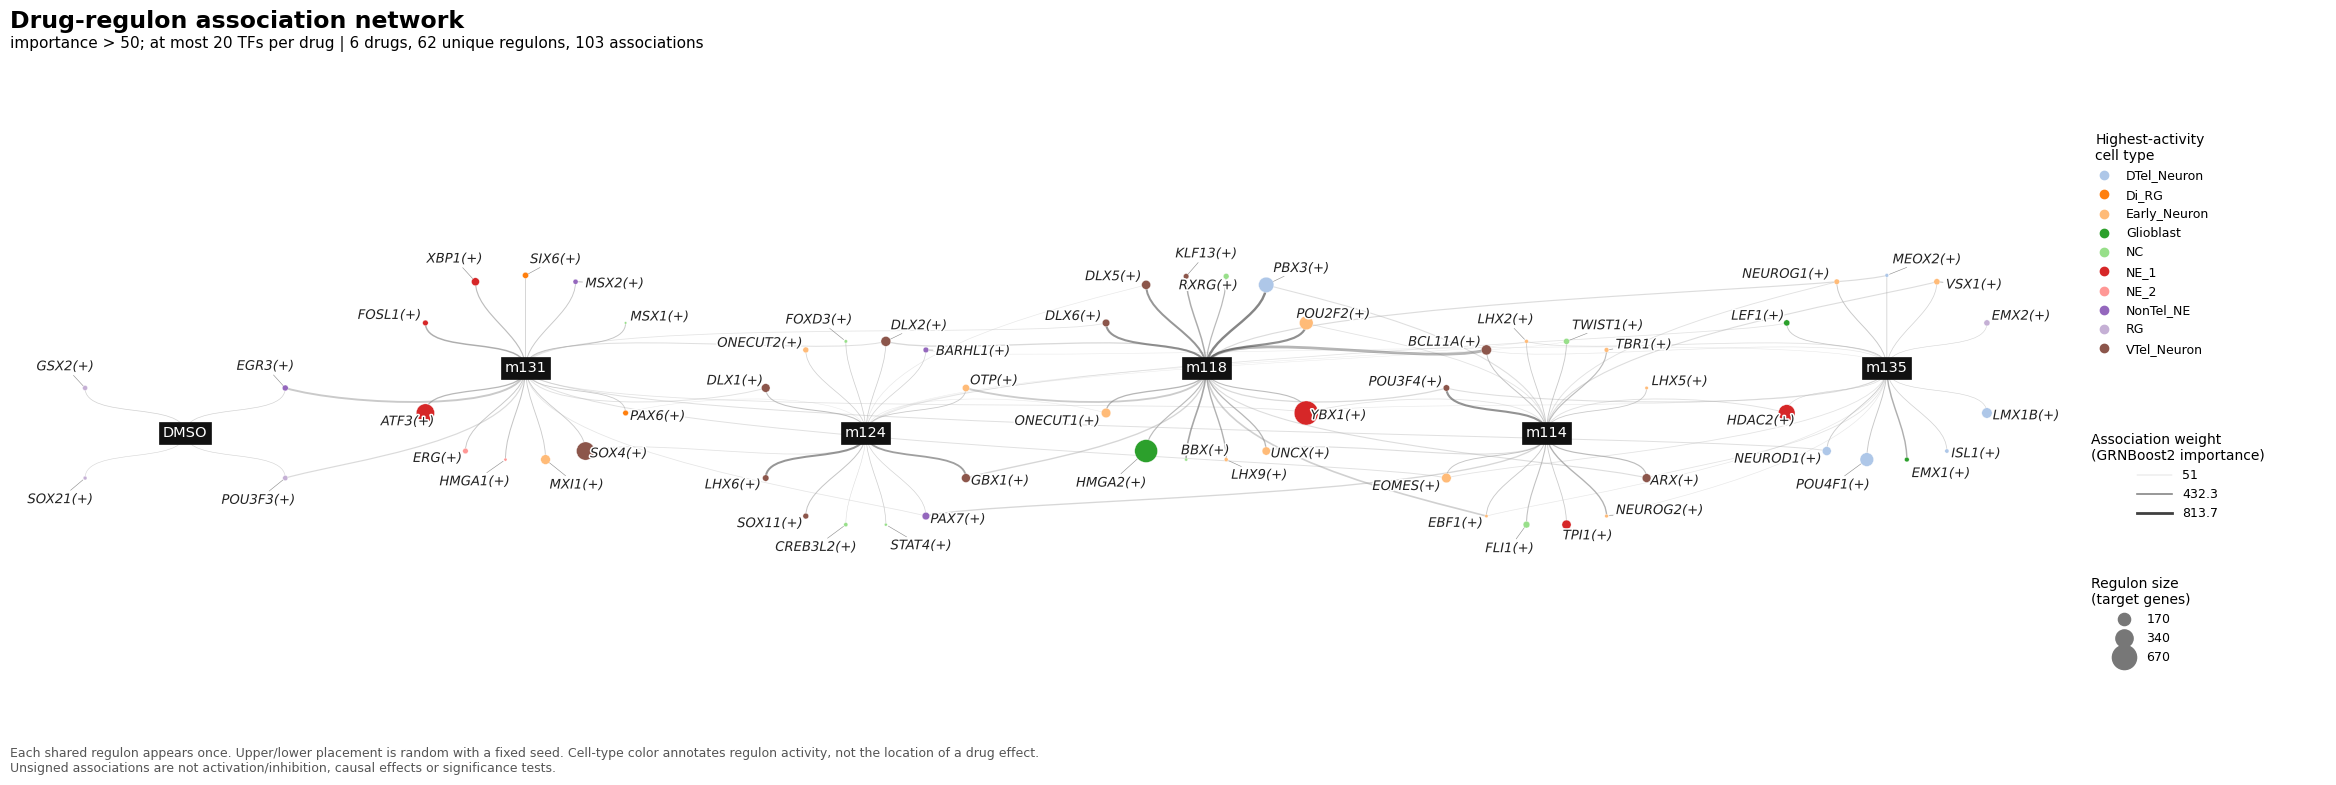

In [8]:
fig, ax, label_artists = draw_panel(edges, tf_positions, drug_positions, celltype_colors, CFG)
plt.show()

## 5. Export and validate

Outputs: vector PDF/SVG, PNG, the selected edges, per-drug filter audit,
TF and drug positions, Jaccard similarity, and a settings/input-hash manifest.
Changing thresholds changes the selected TF sets and therefore the layout.
Existing inference CSVs are only read; generated files use a separate folder.

In [22]:
def export_panel(fig, edges, tf_positions, drug_positions, audit, similarity, colors, cfg):
    output = Path(cfg["output_dir"])
    output.mkdir(parents=True, exist_ok=True)
    assert edges.importance.gt(cfg["min_importance"]).all()
    assert edges.groupby("drug").size().le(cfg["top_n"]).all()
    assert cfg["top_n"] <= 20 and tf_positions.index.is_unique
    assert set(edges.regulon) == set(tf_positions.index)
    assert set(edges.drug).issubset(drug_positions.index)
    paths = {}
    for extension in ["pdf", "svg", "png"]:
        path = output / f"{cfg['output_stem']}.{extension}"
        fig.savefig(path, dpi=cfg["png_dpi"], facecolor="white")
        paths[extension] = str(path)
    edges.to_csv(output / "displayed_edges.csv", index=False)
    tf_positions.to_csv(output / "regulon_positions.csv")
    drug_positions.to_csv(output / "drug_positions.csv")
    audit.to_csv(output / "filter_audit.csv", index=False)
    similarity.to_csv(output / "drug_jaccard_similarity.csv")
    hashes = {key: hashlib.sha256(Path(cfg[key]).read_bytes()).hexdigest()
              for key in ["association_file", "node_file", "target_counts_file"]}
    manifest = {"config": cfg, "input_sha256": hashes, "celltype_colors": colors,
                "n_drugs": len(drug_positions), "n_regulons": len(tf_positions), "n_edges": len(edges),
                "n_shared_regulons": int(tf_positions.shared.sum()),
                "shared_node_policy": "One regulon node; layout host is not a biological assignment",
                "ordering": "Jaccard of displayed TF sets; average linkage with optimal leaf ordering",
                "selection": "Strict raw importance cutoff, then top_n independently per drug; no share cutoff"}
    (output / "plot_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    return paths

In [23]:
saved = export_panel(fig, edges, tf_positions, drug_positions, filter_audit,
                     jaccard_similarity, celltype_colors, CFG)
print("Validated: unique TF nodes, no invented edges, strict threshold, <=20 edges per drug.")
for extension, path in saved.items():
    print(extension.upper(), path)

Validated: unique TF nodes, no invented edges, strict threshold, <=20 edges per drug.
PDF /home/jiafzhou/GRN_org/analysis/drug_regulon_network_with_dmso/figures_drug_select/drug_regulon_fan_panel.pdf
SVG /home/jiafzhou/GRN_org/analysis/drug_regulon_network_with_dmso/figures_drug_select/drug_regulon_fan_panel.svg
PNG /home/jiafzhou/GRN_org/analysis/drug_regulon_network_with_dmso/figures_drug_select/drug_regulon_fan_panel.png


## Fine adjustment

- To use the paper-inspired threshold: `CFG["min_importance"] = 200`.
- To choose fewer TFs: reduce `top_n` (never more than 20).
- To change the random above/below arrangement: change `seed`.
- To spread drug hubs farther: increase `drug_spacing_x` or `drug_spacing_y`.
- To wrap onto fewer rows: increase `drug_columns`.
- To reposition a hub: `drug_positions={"dmso": [0, 1.5]}` in CFG.
- To reposition a shared TF: `regulon_positions={"SOX2(+)": [3, 0]}` in CFG.
- To change label size: adjust `label_fontsize` and `drug_fontsize`.

Rerun from the parameter cell after editing. The position CSVs expose the
automatic layout so manual overrides can be chosen without modifying weights.

Technical references: [Matplotlib paths](https://matplotlib.org/stable/api/path_api.html),
[SciPy assignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html),
[optimal leaf ordering](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.optimal_leaf_ordering.html).